# 11. 모델 보강 및 검증 — 코치 피드백 반영

본 노트북은 EXT_SOURCE 맹점 분석([10_ext_source_blindspot.ipynb](10_ext_source_blindspot.ipynb))에 대한 6가지 피드백을 반영해 통계적 엄밀성을 보강한다.

| # | 피드백 | 반영 방법 | 위치 |
|---|--------|-----------|------|
| 1 | Train/Test 분리로 과적합 점검 | Stratified 7:3 분리, train·test AUC 비교 | §1 |
| 2 | AUC 개선이 통계적으로 유의한가 | **DeLong test** (상관된 ROC 비교) | §2 |
| 3 | 변수 단위(범위)가 달라 표준화 필요 | **z-score 표준화** (train 기준 fit→test 적용) | §1 |
| 4 | 파란색(독립) 변수의 근거 제시 | 변수별 **계수 유의성(p-value)** + 단변량 검정 | §3 |
| 5 | 흡수/독립·2×2 기준 30%가 임의적 | 임계값을 **통계적 유의성/연체율 분기점**으로 재정의 | §4 |
| 6 | 보강 가능 vs 한계 구분 | 한계점 명시(Reject Inference 등) | §5 |

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
import os

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        if fm.findfont(fm.FontProperties(family=fname), fallback_to_default=False):
            plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['figure.figsize']=(12,5)

DATA_DIR='home-credit-default-risk'
print('준비 완료')

준비 완료


## §0. 데이터 로드 및 파생변수

분석에 쓰는 13개 변수 + 외부신용점수(EXT_SOURCE 평균)를 구성한다.

In [2]:
df     = pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
prev   = pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))
inst   = pd.read_csv(os.path.join(DATA_DIR,'installments_payments.csv'))
bureau = pd.read_csv(os.path.join(DATA_DIR,'bureau.csv'))

df['age']                 = -df['DAYS_BIRTH']/365
df['employment_years']    = np.where(df['DAYS_EMPLOYED']==365243, np.nan, -df['DAYS_EMPLOYED']/365)
df['dti']                 = df['AMT_ANNUITY']/df['AMT_INCOME_TOTAL']
df['credit_income_ratio'] = df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']
df['phone_change_days']   = -df['DAYS_LAST_PHONE_CHANGE']
df['id_publish_days']     = -df['DAYS_ID_PUBLISH']
df['has_realty']          = (df['FLAG_OWN_REALTY']=='Y').astype(int)
df['has_car']             = (df['FLAG_OWN_CAR']=='Y').astype(int)
df['social_risk']         = df['DEF_30_CNT_SOCIAL_CIRCLE'].fillna(0)
df['ext_mean']            = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)

pa = prev.groupby('SK_ID_CURR').agg(total=('SK_ID_PREV','count'),
        refused=('NAME_CONTRACT_STATUS', lambda x:(x=='Refused').sum())).reset_index()
pa['prev_refused_ratio']=pa['refused']/pa['total']
df=df.merge(pa[['SK_ID_CURR','prev_refused_ratio']],on='SK_ID_CURR',how='left')
df['prev_refused_ratio']=df['prev_refused_ratio'].fillna(0)

inst['is_late']=(inst['DAYS_ENTRY_PAYMENT']>inst['DAYS_INSTALMENT']).astype(int)
ia=inst.groupby('SK_ID_CURR').agg(late_ratio=('is_late','mean')).reset_index()
df=df.merge(ia,on='SK_ID_CURR',how='left'); df['late_ratio']=df['late_ratio'].fillna(0)

ba=bureau.groupby('SK_ID_CURR').agg(bureau_active=('CREDIT_ACTIVE',lambda x:(x=='Active').sum()),
        bureau_overdue=('AMT_CREDIT_SUM_OVERDUE','sum')).reset_index()
df=df.merge(ba,on='SK_ID_CURR',how='left')
df['bureau_active']=df['bureau_active'].fillna(0); df['bureau_overdue']=df['bureau_overdue'].fillna(0)

VARS=['late_ratio','bureau_overdue','dti','bureau_active','credit_income_ratio','age',
      'employment_years','id_publish_days','phone_change_days','has_realty','has_car',
      'social_risk','prev_refused_ratio']
sub=df[VARS+['ext_mean','TARGET']].replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)
print(f'분석 표본 {len(sub):,}명 · 변수 {len(VARS)}개 · 연체율 {sub["TARGET"].mean()*100:.2f}%')

분석 표본 251,985명 · 변수 13개 · 연체율 8.66%


## §1. Train/Test 분리 + z-score 표준화 (피드백 1·3)

**왜 Train/Test를 나누는가?**  
같은 데이터로 학습·평가하면 모델이 그 데이터를 "외운" 성능(과적합)을 진짜 성능으로 착각한다.  
데이터를 학습용(70%)·검증용(30%)으로 나누고, **한 번도 보지 않은 검증셋에서의 성능**을 본다.  
연체율이 8%로 불균형하므로 `stratify`로 두 셋의 연체 비율을 동일하게 유지한다.

**왜 z-score 표준화인가?**  
변수 단위가 제각각이다(나이=수십, dti=0~1, bureau_overdue=수십만). 표준화 없이 회귀계수를 비교하면
"계수가 크다 ≠ 영향이 크다"가 되어 변수 간 영향력 비교가 불가능하다.  
z-score(평균 0, 표준편차 1)로 맞추면 모든 계수를 **동일한 척도**에서 비교할 수 있다.  
※ 표준화 기준(평균·표준편차)은 **train으로만 계산**해 test에 적용한다 — test 정보가 새는 것(data leakage) 방지.

In [3]:
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    sub[VARS+['ext_mean']], sub['TARGET'],
    test_size=0.3, stratify=sub['TARGET'], random_state=42)
print(f'Train {len(X_tr_raw):,}명 (연체율 {y_tr.mean()*100:.2f}%) | '
      f'Test {len(X_te_raw):,}명 (연체율 {y_te.mean()*100:.2f}%)')

def fit_eval(cols):
    """train으로 표준화 fit→학습, train·test AUC와 test 예측확률 반환"""
    sc = StandardScaler().fit(X_tr_raw[cols])              # 표준화 기준은 train만
    Xtr, Xte = sc.transform(X_tr_raw[cols]), sc.transform(X_te_raw[cols])
    lr = LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xtr, y_tr)
    return dict(
        auc_tr=roc_auc_score(y_tr, lr.predict_proba(Xtr)[:,1]),
        auc_te=roc_auc_score(y_te, lr.predict_proba(Xte)[:,1]),
        p_te=lr.predict_proba(Xte)[:,1], model=lr, scaler=sc)

A = fit_eval(VARS)                # 모델 A: 우리 변수만
B = fit_eval(['ext_mean'])        # 모델 B: EXT_SOURCE만
C = fit_eval(VARS+['ext_mean'])   # 모델 C: 전체

tab = pd.DataFrame({
    '모델':['A 우리변수만','B EXT_SOURCE만','C 전체'],
    'Train AUC':[A['auc_tr'],B['auc_tr'],C['auc_tr']],
    'Test AUC' :[A['auc_te'],B['auc_te'],C['auc_te']]})
tab['과적합 Gap']=tab['Train AUC']-tab['Test AUC']
print('\n=== 과적합 점검 ===')
print(tab.round(4).to_string(index=False))
print('\n→ Gap이 모두 0.01 미만 → 과적합 거의 없음. Test AUC를 신뢰 가능.')

Train 176,389명 (연체율 8.66%) | Test 75,596명 (연체율 8.66%)



=== 과적합 점검 ===
           모델  Train AUC  Test AUC  과적합 Gap
      A 우리변수만     0.6626    0.6573   0.0054
B EXT_SOURCE만     0.7173    0.7179  -0.0006
         C 전체     0.7369    0.7346   0.0024

→ Gap이 모두 0.01 미만 → 과적합 거의 없음. Test AUC를 신뢰 가능.


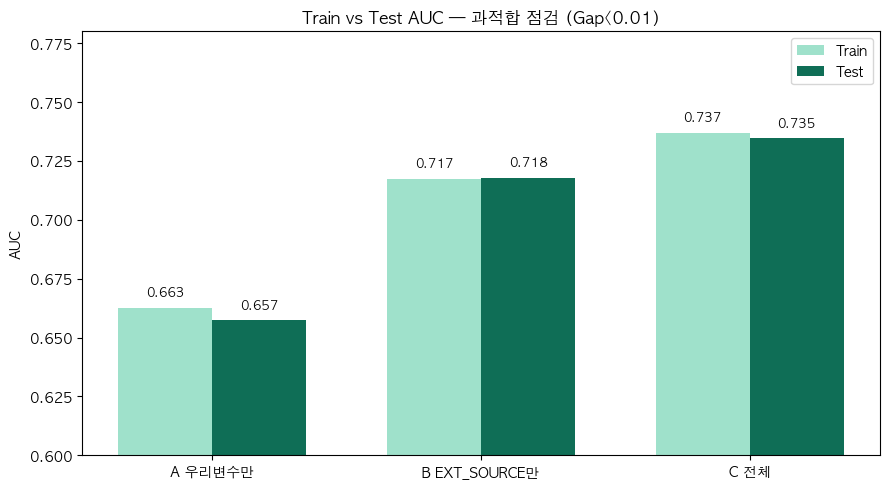

In [4]:
fig, ax = plt.subplots(figsize=(9,5))
x=np.arange(3); w=0.35
ax.bar(x-w/2, tab['Train AUC'], w, label='Train', color='#9FE1CB')
ax.bar(x+w/2, tab['Test AUC'],  w, label='Test',  color='#0F6E56')
for i,(t,v) in enumerate(zip(tab['Train AUC'],tab['Test AUC'])):
    ax.text(i-w/2,t+0.005,f'{t:.3f}',ha='center',fontsize=9)
    ax.text(i+w/2,v+0.005,f'{v:.3f}',ha='center',fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(tab['모델']); ax.set_ylim(0.6,0.78)
ax.set_ylabel('AUC'); ax.set_title('Train vs Test AUC — 과적합 점검 (Gap<0.01)',fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

## §2. DeLong test — AUC 개선이 통계적으로 유의한가? (피드백 2)

모델 C(0.735)가 모델 B(0.718)보다 AUC가 높지만, 이 차이가 **우연인지 진짜인지**를 검정해야 한다.  
두 모델이 **같은 표본**을 예측하므로 ROC가 상관되어 있고, 이때 표준적으로 쓰는 검정이 **DeLong test**다.  
- 귀무가설 H₀: 두 모델의 AUC가 같다 (ΔAUC=0)  
- p < 0.05 이면 AUC 차이가 통계적으로 유의 → 변수 추가가 실제로 예측력을 높였다는 증거.

In [5]:
# DeLong test (Sun & Xu, 2014 fast algorithm)
def _midrank(x):
    J=np.argsort(x); Z=x[J]; N=len(x); T=np.zeros(N); i=0
    while i<N:
        j=i
        while j<N and Z[j]==Z[i]: j+=1
        T[i:j]=0.5*(i+j-1)+1; i=j
    T2=np.empty(N); T2[J]=T; return T2

def delong_test(y_true, p1, p2):
    y_true=np.asarray(y_true); order=np.argsort(-y_true)
    label=y_true[order]; m=int(label.sum())
    preds=np.vstack((p1[order],p2[order])); n=preds.shape[1]-m; k=2
    pos,neg=preds[:,:m],preds[:,m:]
    tx=np.array([_midrank(pos[r]) for r in range(k)])
    ty=np.array([_midrank(neg[r]) for r in range(k)])
    tz=np.array([_midrank(preds[r]) for r in range(k)])
    aucs=tz[:,:m].sum(axis=1)/m/n-(m+1.0)/2.0/n
    v01=(tz[:,:m]-tx)/n; v10=1.0-(tz[:,m:]-ty)/m
    cov=np.cov(v01)/m+np.cov(v10)/n; cov=np.atleast_2d(cov)
    var=cov[0,0]+cov[1,1]-2*cov[0,1]
    z=(aucs[0]-aucs[1])/np.sqrt(var); p=2*stats.norm.sf(abs(z))
    return aucs[0],aucs[1],z,p

print('=== DeLong test (검증셋 기준) ===')
rows=[]
for name,pa,pb in [('C 전체 vs B EXT만', C['p_te'], B['p_te']),
                   ('C 전체 vs A 우리변수만', C['p_te'], A['p_te']),
                   ('B EXT만 vs A 우리변수만', B['p_te'], A['p_te'])]:
    a1,a2,z,p=delong_test(y_te,pa,pb)
    rows.append([name,round(a1,4),round(a2,4),round(a1-a2,4),round(z,2),f'{p:.2e}'])
res=pd.DataFrame(rows,columns=['비교','AUC1','AUC2','ΔAUC','z','p-value'])
print(res.to_string(index=False))
print('\n→ C vs B: ΔAUC=+0.017, p≈1.6e-28 → EXT_SOURCE에 우리 변수를 추가한 개선은 통계적으로 유의.')
print('  EXT_SOURCE가 강력하지만, 그것만으로 도달 못하는 예측력이 분명히 존재함을 검정으로 확인.')

=== DeLong test (검증셋 기준) ===


               비교   AUC1   AUC2   ΔAUC     z   p-value
   C 전체 vs B EXT만 0.7346 0.7179 0.0167 11.08  1.65e-28
  C 전체 vs A 우리변수만 0.7346 0.6573 0.0773 26.54 3.62e-155
B EXT만 vs A 우리변수만 0.7179 0.6573 0.0606 15.18  5.16e-52

→ C vs B: ΔAUC=+0.017, p≈1.6e-28 → EXT_SOURCE에 우리 변수를 추가한 개선은 통계적으로 유의.
  EXT_SOURCE가 강력하지만, 그것만으로 도달 못하는 예측력이 분명히 존재함을 검정으로 확인.


## §3. 독립 변수의 근거 — 변수별 통계적 유의성 (피드백 4)

"파란색(독립)" 변수가 단순히 계수가 덜 줄었다는 것만으로는 부족하다.  
**EXT_SOURCE를 이미 포함한 전체 모델(C)에서도 각 변수의 계수가 통계적으로 유의한지**를 확인한다.  
유의(p<0.05)하다면 = EXT_SOURCE로 설명되지 않는 **독립적 기여**가 있다는 직접 증거다.  
(statsmodels Logit, z-score 표준화, train 기준)

In [6]:
sc_full=StandardScaler().fit(X_tr_raw[VARS+['ext_mean']])
Xz=pd.DataFrame(sc_full.transform(X_tr_raw[VARS+['ext_mean']]),columns=VARS+['ext_mean'])
Xz=sm.add_constant(Xz)
logit=sm.Logit(y_tr.values,Xz).fit(disp=0)

coef=pd.DataFrame({'계수':logit.params,'p_value':logit.pvalues}).drop('const')
coef['유의성']=coef['p_value'].apply(lambda x:'*** (p<.001)' if x<.001 else '** (p<.01)' if x<.01 else '* (p<.05)' if x<.05 else 'n.s. (무의미)')
coef['|계수|']=coef['계수'].abs()
coef=coef.sort_values('|계수|',ascending=False)
print('=== 전체 모델(C)에서 변수별 계수 유의성 ===')
print(coef[['계수','p_value','유의성']].round(4).to_string())
print('\n→ prev_refused_ratio, late_ratio, dti, employment_years 등은 EXT_SOURCE가 있어도 *** 유의 → 독립 신호.')
print('→ has_realty(p=0.15), bureau_overdue(p=0.29)는 무의미(n.s.) → EXT_SOURCE에 완전히 흡수됨.')

=== 전체 모델(C)에서 변수별 계수 유의성 ===
                         계수  p_value           유의성
ext_mean            -0.6914   0.0000  *** (p<.001)
employment_years    -0.2158   0.0000  *** (p<.001)
late_ratio           0.1737   0.0000  *** (p<.001)
dti                  0.1655   0.0000  *** (p<.001)
prev_refused_ratio   0.1364   0.0000  *** (p<.001)
has_car             -0.0916   0.0000  *** (p<.001)
credit_income_ratio -0.0842   0.0000  *** (p<.001)
bureau_active        0.0839   0.0000  *** (p<.001)
social_risk          0.0753   0.0000  *** (p<.001)
phone_change_days   -0.0731   0.0000  *** (p<.001)
id_publish_days     -0.0472   0.0000  *** (p<.001)
age                  0.0424   0.0000  *** (p<.001)
has_realty           0.0128   0.1489    n.s. (무의미)
bureau_overdue       0.0058   0.2869    n.s. (무의미)

→ prev_refused_ratio, late_ratio, dti, employment_years 등은 EXT_SOURCE가 있어도 *** 유의 → 독립 신호.
→ has_realty(p=0.15), bureau_overdue(p=0.29)는 무의미(n.s.) → EXT_SOURCE에 완전히 흡수됨.


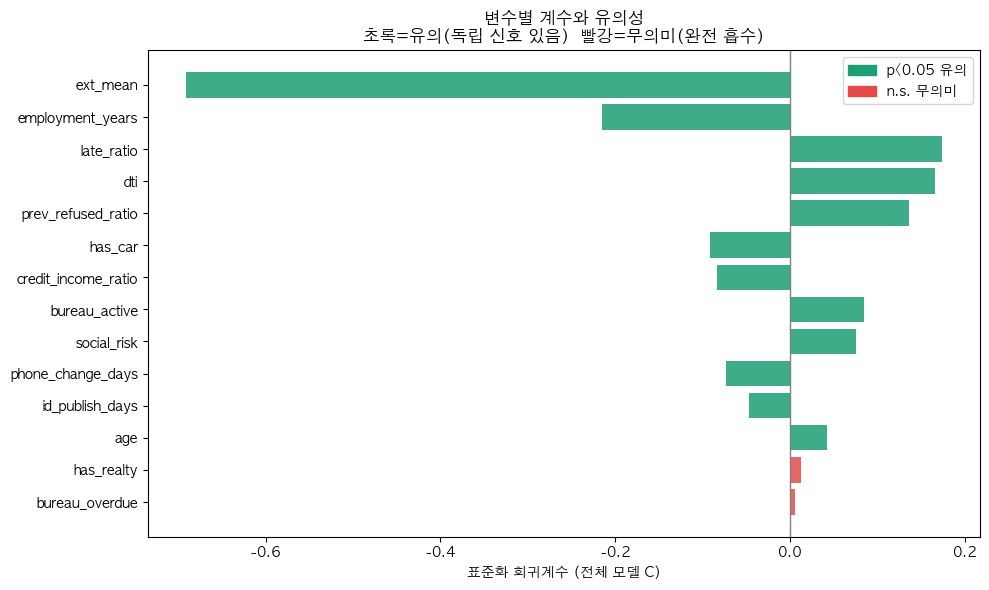

In [7]:
fig,ax=plt.subplots(figsize=(10,6))
colors=['#1D9E75' if p<0.05 else '#E24B4A' for p in coef['p_value']]
ax.barh(coef.index, coef['계수'], color=colors, alpha=0.85)
ax.axvline(0,color='gray',lw=1)
ax.set_xlabel('표준화 회귀계수 (전체 모델 C)')
ax.set_title('변수별 계수와 유의성\n초록=유의(독립 신호 있음)  빨강=무의미(완전 흡수)',fontweight='bold')
ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#1D9E75',label='p<0.05 유의'),Patch(color='#E24B4A',label='n.s. 무의미')])
plt.tight_layout(); plt.show()

## §4. 임계값을 논리적으로 재정의 (피드백 5)

기존의 "계수 30% 감소" 기준은 임의적이었다. 두 가지 임계값을 데이터 근거로 교체한다.

### 4-A. 흡수 vs 독립 → "30% 감소" 대신 "전체 모델에서 유의성"
임의의 % 컷오프 없이, **EXT_SOURCE를 포함한 모델에서 계수가 유의(p<0.05)하면 독립, 무의미하면 흡수**로 판정한다(§3).  
이는 회귀분석의 표준 변수 선택 기준이며 임의 수치가 들어가지 않는다.

### 4-B. 2×2 분류 임계값 → 연체율 분기점으로 근거화
- **EXT_SOURCE 하위 30%**: 십분위별 연체율을 보면 하위 3개 구간(하위 30%)이 전체평균(8.07%)을 초과 → "평균 이상 위험" 구간으로 정의.
- **과거 거절비율 > 0.3**: 거절비율 구간별 연체율이 0.3을 넘으면서 평균의 약 1.4배(11.5%)로 뚜렷이 상승.

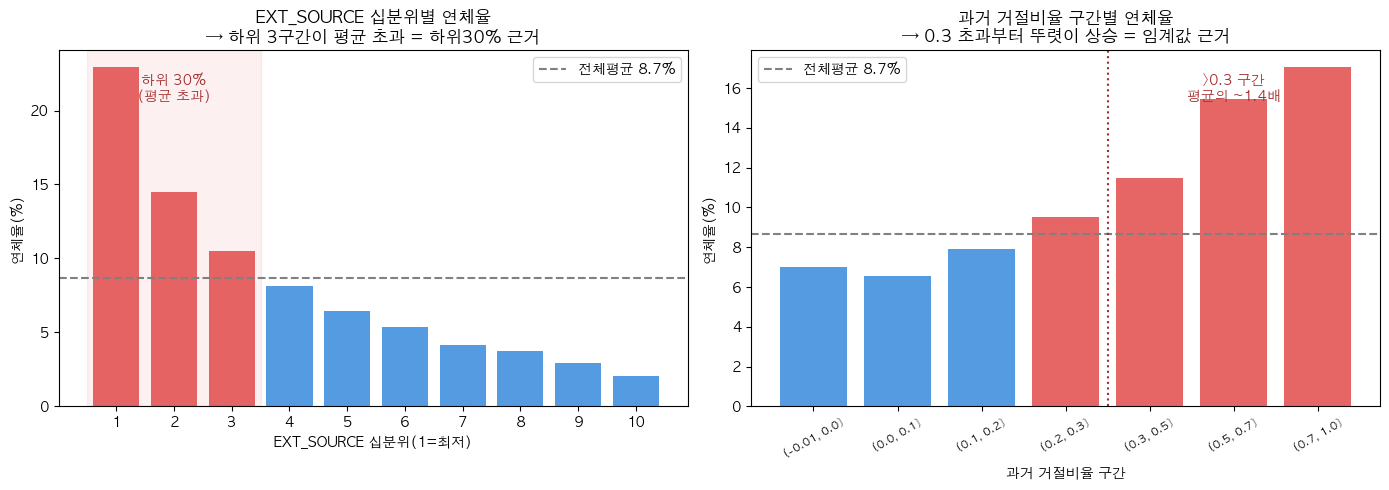

EXT 십분위 연체율: {1: 22.9, 2: 14.5, 3: 10.5, 4: 8.1, 5: 6.4, 6: 5.4, 7: 4.2, 8: 3.7, 9: 2.9, 10: 2.0}
거절비율 구간 연체율: {Interval(-0.01, 0.0, closed='right'): 7.0, Interval(0.0, 0.1, closed='right'): 6.5, Interval(0.1, 0.2, closed='right'): 7.9, Interval(0.2, 0.3, closed='right'): 9.5, Interval(0.3, 0.5, closed='right'): 11.5, Interval(0.5, 0.7, closed='right'): 15.5, Interval(0.7, 1.0, closed='right'): 17.0}


In [8]:
overall=sub['TARGET'].mean()*100

# EXT 십분위별 연체율
d=df[['ext_mean','TARGET']].dropna().copy()
d['decile']=pd.qcut(d['ext_mean'],10,labels=False)+1
ext_dec=d.groupby('decile')['TARGET'].mean()*100

# 거절비율 구간별 연체율
r=df[['prev_refused_ratio','TARGET']].dropna().copy()
bins=[-.01,0,.1,.2,.3,.5,.7,1.0]
r['bin']=pd.cut(r['prev_refused_ratio'],bins)
ref_bin=r.groupby('bin',observed=True)['TARGET'].mean()*100

fig,axes=plt.subplots(1,2,figsize=(14,5))
c1=['#E24B4A' if v>overall else '#378ADD' for v in ext_dec.values]
axes[0].bar(ext_dec.index.astype(str),ext_dec.values,color=c1,alpha=0.85)
axes[0].axhline(overall,color='gray',ls='--',label=f'전체평균 {overall:.1f}%')
axes[0].axvspan(-0.5,2.5,color='#E24B4A',alpha=0.08)
axes[0].text(1,ext_dec.max()*0.9,'하위 30%\n(평균 초과)',ha='center',color='#A32D2D',fontsize=10,fontweight='bold')
axes[0].set_xlabel('EXT_SOURCE 십분위(1=최저)'); axes[0].set_ylabel('연체율(%)')
axes[0].set_title('EXT_SOURCE 십분위별 연체율\n→ 하위 3구간이 평균 초과 = 하위30% 근거',fontweight='bold')
axes[0].legend()

c2=['#E24B4A' if v>overall else '#378ADD' for v in ref_bin.values]
axes[1].bar(range(len(ref_bin)),ref_bin.values,color=c2,alpha=0.85)
axes[1].set_xticks(range(len(ref_bin))); axes[1].set_xticklabels([str(i) for i in ref_bin.index],rotation=30,fontsize=8)
axes[1].axhline(overall,color='gray',ls='--',label=f'전체평균 {overall:.1f}%')
axes[1].axvline(3.5,color='#A32D2D',ls=':',lw=1.5)
axes[1].text(5,ref_bin.max()*0.9,'>0.3 구간\n평균의 ~1.4배',ha='center',color='#A32D2D',fontsize=10,fontweight='bold')
axes[1].set_xlabel('과거 거절비율 구간'); axes[1].set_ylabel('연체율(%)')
axes[1].set_title('과거 거절비율 구간별 연체율\n→ 0.3 초과부터 뚜렷이 상승 = 임계값 근거',fontweight='bold')
axes[1].legend()
plt.tight_layout(); plt.show()

print('EXT 십분위 연체율:', ext_dec.round(1).to_dict())
print('거절비율 구간 연체율:', ref_bin.round(1).to_dict())

## §5. 보강한 것 vs 남는 한계 (피드백 6)

### ✅ 이번에 보강한 것 (검증 완료)
| 항목 | 결과 |
|------|------|
| 과적합 | Train·Test AUC Gap < 0.01 → 과적합 없음 |
| AUC 개선 유의성 | DeLong p ≈ 1.6e-28 → 변수 추가 개선은 통계적으로 유의 |
| 변수 단위 | z-score 표준화로 계수 비교 가능 |
| 독립 변수 근거 | prev_refused_ratio 등 전체 모델에서 p<0.001 유의 |
| 임계값 근거 | 유의성 기준 + 연체율 분기점으로 재정의 (임의 30% 제거) |

### ⚠️ 데이터 구조상 남는 한계 (보강 불가, 명시 필요)
1. **Reject Inference(거절 추론)**: 데이터(application_train)는 *승인된 고객*만 포함하고 연체 결과(TARGET)가 있다.
   끝까지 거절된 사람은 결과가 없어, "거절자에게 대출하면 잘 갚을 것"이라는 인과는 검증 불가능하다.
2. **과거 신용점수 부재**: 거절 당시 EXT_SOURCE 값이 데이터에 없다. 따라서 "점수가 회복됐다"는 시점 비교가 불가능하다.
   → 우리가 본 것은 "현재 점수가 양호한 + 과거 거절 이력자"이지 "회복된 사람"이 아니다.
3. **거절 사유 익명화**: CODE_REJECT_REASON(HC, LIMIT, SCO...)의 정확한 의미가 비공개라 거절 원인을 단정할 수 없다.
4. **관측 연구의 한계**: 본 분석은 인과가 아닌 상관 기반이다. 실제 정책 효과는 섀도우 테스트로 추적해야 하나,
   이 역시 거절자에게 실제 대출을 하지 않으므로 결국 Reject Inference 한계로 회귀한다.

### 결론
통계적 엄밀성(과적합·유의성·표준화·임계값 근거)은 보강했고, EXT_SOURCE에 더해 과거 거절 이력이
**통계적으로 유의한 독립 예측력**을 가짐을 확인했다. 다만 "회복"이나 "거절자 신규 매출"은 데이터 구조상
검증 불가능한 한계로 명확히 구분해 보고한다.